# Batch correction with scVI

scVI (Lopez *et al.*, *Nat Methods* 2018) is a variational autoencoder for
scRNA-seq counts: the encoder maps each cell to a low-dimensional latent `z`,
the decoder — conditioned on the batch — reconstructs the counts with a
zero-inflated negative-binomial likelihood. Because batch is given to the
decoder, `z` does not need to encode it, so the latent space is largely
batch-free while keeping cell-type structure. Good default for many batches
and uneven composition.


> **Backend.** Since omicverse 2.4 the scVI family (`'scVI'`, `'scANVI'`,
> `'totalVI'`) runs on **`ov.vi`** — omicverse's own PyTorch implementation
> (scvi-tools-compatible API and defaults, no scvi-tools / Lightning
> dependency). It trains on in-memory AnnData, disk-backed AnnDataOOM
> (`ov.read(path, storage='disk')`) and Dask-backed AnnData (GPU mode). See
> [t_vi](../t_vi.ipynb) for the direct `ov.vi` API, disk and GPU training.


This is one of the **omicverse batch-correction zoo** tutorials. See
[batch/index](../index.md) for the overview / decision tree, or
[../t_single_batch](../t_single_batch.ipynb) for the side-by-side comparison of
every backend.

## Load the NeurIPS 2021 bone-marrow data (3 donors)

Bone-marrow mononuclear cells from the NeurIPS 2021 multimodal single-cell
integration benchmark (Luecken *et al.*, NeurIPS Datasets & Benchmarks 2021),
gene-expression part of the CITE-seq arm: three donors measured at three
different sites (`s1d3`, `s2d1`, `s3d7`) — each donor/site is one batch — with
the authors' cell-type annotation in `obs['cell_type']`. The files store raw
counts in `layers['counts']` and normalised values in `X`; scVI-family models
need the **raw counts**, so we put them back into `X` before preprocessing.

The zoo notebooks use a 6 000-cell random subsample so every backend runs in
minutes; [t_vi](../t_vi.ipynb) uses all 27 423 cells.

In [1]:
import omicverse as ov
import anndata as ad
import numpy as np
import pandas as pd
ov.style()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…


✅ NVIDIA CUDA GPUs detected: 1
    • [CUDA 0] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: unknown   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [2]:
adata1 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932005', filename='neurips2021_s1d3.h5ad')
adata2 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932008', filename='neurips2021_s2d1.h5ad')
adata3 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932011', filename='neurips2021_s3d7.h5ad')

⚠️ File ./data/neurips2021_s1d3.h5ad already exists
 Loading data from ./data/neurips2021_s1d3.h5ad


✅ Successfully loaded: 5935 cells × 13953 genes
⚠️ File ./data/neurips2021_s2d1.h5ad already exists
 Loading data from ./data/neurips2021_s2d1.h5ad


✅ Successfully loaded: 10258 cells × 13953 genes
⚠️ File ./data/neurips2021_s3d7.h5ad already exists
 Loading data from ./data/neurips2021_s3d7.h5ad


✅ Successfully loaded: 11230 cells × 13953 genes


In [3]:
adata = ad.concat([adata1, adata2, adata3], merge='same')
adata.X = adata.layers['counts'].copy()   # raw counts back into X
adata.obs['batch'] = adata.obs['batch'].astype('category')
adata

AnnData object with n_obs × n_vars = 27423 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train'
    var: 'feature_types', 'gene_id'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
    layers: 'counts', None (.X)

In [4]:
sel = np.random.default_rng(0).choice(adata.n_obs, 6000, replace=False)
adata = adata[np.sort(sel)].copy()
adata.obs['batch'].value_counts()

batch
s3d7    2442
s2d1    2270
s1d3    1288
Name: count, dtype: int64

## Preprocess

The zoo-wide pipeline: QC → size normalisation + log → 2 000 HVGs (Pearson
residuals) → scaled PCA. `ov.pp.preprocess` keeps the raw counts in
`layers['counts']`, which is what the scVI family trains on. The NeurIPS cells
are already filtered, so the QC thresholds are loose and doublet detection is
skipped.

In [5]:
adata = ov.pp.qc(adata, tresh={'mito_perc': 0.2, 'nUMIs': 500, 'detected_genes': 250},
                 doublets=False)
adata = ov.pp.preprocess(adata, mode='shiftlog|pearson', n_HVGs=2000)

🖥️ Using CPU mode for QC...
   Auto-detected mitochondrial prefix: 'MT-'

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 13                 │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 94                 │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Hemoglobin                   │ 11                 │ Auto (regex)       │
   └──────────────────────────────┴────────────────────┴────────────────────┘

   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range 

   ✓ Final filtering: 0 cells, 0 genes removed

📊 Step 4: Doublet detection disabled

╭─ SUMMARY: qc ──────────────────────────────────────────────────────╮
│  Duration: 0.3233s                                                 │
│  Shape:    6,000 x 13,953 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBS    │ ✚ cell_complexity (float)                              │
│           │ ✚ detected_genes (int)                                 │
│           │ ✚ hb_perc (float)                                      │
│           │ ✚ mito_perc (float)                                    │
│           │ ✚ nUMIs (float)                                        │
│           │ ✚ n_counts (float)                                     │
│           │ ✚ n_genes (int)                                 


✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 13,953 total (14.3%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 0.73 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ───────────────────

In [6]:
adata.raw = adata
adata = adata[:, adata.var.highly_variable_features].copy()
ov.pp.scale(adata)
ov.pp.pca(adata, layer='scaled', n_pcs=30)


╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 0.0333s                                                 │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● LAYERS │ ✚ scaled (array, 5895x2000)                            │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
computing PCA🔍
    with n_comps=30
   🖥️ Using sklearn PCA for CPU computation
   🖥️ sklearn PCA backend: CPU computation
   📊 PCA input data type: ArrayView, shape: (5895, 2000), dtype: float64


   🔧 PCA solver used: covariance_eigh
    finished✅ (1.53s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 1.5368s                                                 │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 5895x30)                               │
│           │ ✚ scaled|original|X_pca (array, 5895x30)               │
│         

## Uncorrected baseline

UMAP of the uncorrected PCA: cells separate by donor within most cell types —
the batch effect we want to remove.

🖥️ Using Scanpy CPU to calculate neighbors...

🔍 K-Nearest Neighbors Graph Construction:
   Mode: cpu
   Neighbors: 15
   Method: umap
   Metric: euclidean
   Representation: scaled|original|X_pca
   🔍 Computing neighbor distances...


   🔍 Computing connectivity matrix...
   💡 Using UMAP-style connectivity
   ✓ Graph is fully connected

✅ KNN Graph Construction Completed Successfully!
   ✓ Processed: 5,895 cells with 15 neighbors each
   ✓ Results added to AnnData object:
     • 'neighbors': Neighbors metadata (adata.uns)
     • 'distances': Distance matrix (adata.obsp)
     • 'connectivities': Connectivity matrix (adata.obsp)

╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 0.3627s                                                 │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ neighbors                                            │
│           │ └─ params: {'n_neighbors': 15, 'method': 'umap', 'random_s...│
│                        

   🔍 Computing UMAP parameters...
   🔍 Computing UMAP embedding (classic method)...



✅ UMAP Dimensionality Reduction Completed Successfully!
   ✓ Embedding shape: 5,895 cells × 2 dimensions
   ✓ Results added to AnnData object:
     • 'X_umap': UMAP coordinates (adata.obsm)
     • 'umap': UMAP parameters (adata.uns)
✅ UMAP completed successfully.

╭─ SUMMARY: umap ────────────────────────────────────────────────────╮
│  Duration: 9.5479s                                                 │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ umap                                                 │
│           │ └─ params: {'a': np.float64(0.5830300203414425), 'b': np.f...│
│                                                                    │
│  ● OBSM   │ ✚ X_umap (array, 5895x2)                               │
│                 

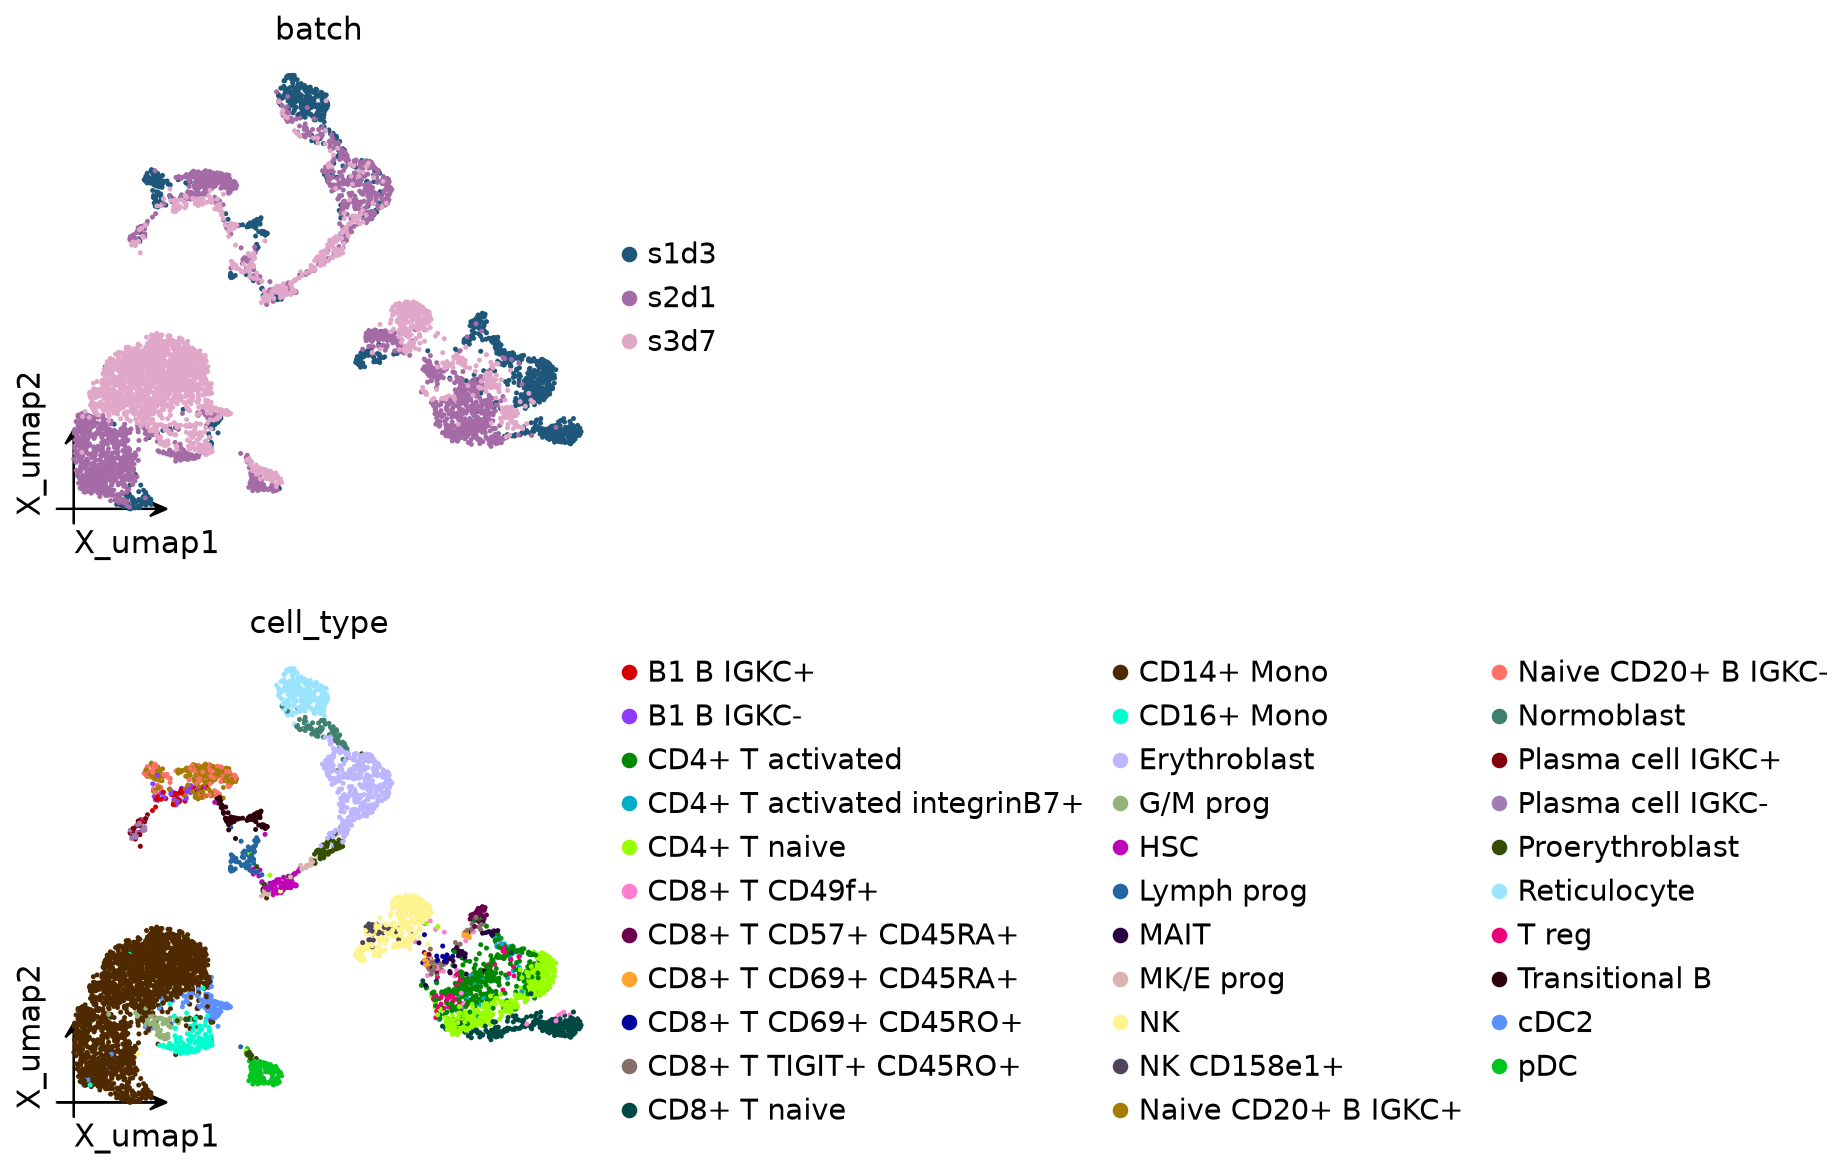

In [7]:
ov.pp.neighbors(adata, use_rep='scaled|original|X_pca', n_neighbors=15)
ov.pp.umap(adata)
ov.pl.embedding(adata, basis='X_umap', color=['batch', 'cell_type'],
                frameon='small', wspace=0.65)

## Run `ov.single.batch_correction(methods='scVI')`

Two hidden layers and a 30-dimensional latent (the settings of the scVI
integration benchmarks); validation ELBO every 10 epochs so we can look at the
training curve. `max_epochs` is left at the scvi-tools heuristic
(`min(round(20000 / n_cells * 400), 400)` → 400 for 6 000 cells); CUDA is used
when available.

In [8]:
model = ov.single.batch_correction(adata, batch_key='batch', methods='scVI',
                                   n_layers=2, n_latent=30,
                                   check_val_every_n_epoch=10)
model

...Begin using scVI to correct batch effect


Training:   0%|          | 0/400 [00:00<?, ?epoch/s]


╭─ SUMMARY: batch_correction ────────────────────────────────────────╮
│  Duration: 18.2757s                                                │
│  Shape:    5,895 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBSM   │ ✚ X_scVI (array, 5895x30)                              │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯


SCVI(n_obs=5895, n_vars=2000, n_batch=3, n_labels=1, layer='counts', trained=True)

The call returns the trained `ov.vi.SCVI` and writes the latent to
`adata.obsm['X_scVI']`. Training and validation negative ELBO should fall and
flatten without the validation curve turning up (no overfitting):

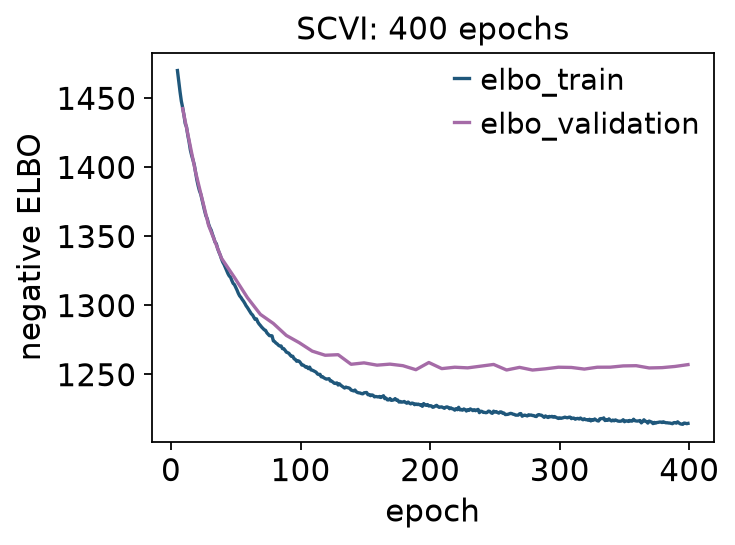

In [9]:
ov.vi.plot_history(model, skip_first=5);

## Corrected embedding

A 2-D MDE of the scVI latent (`ov.vi.mde`, GPU when available): donors should
now overlap inside each cell type, and the cell types stay separated.

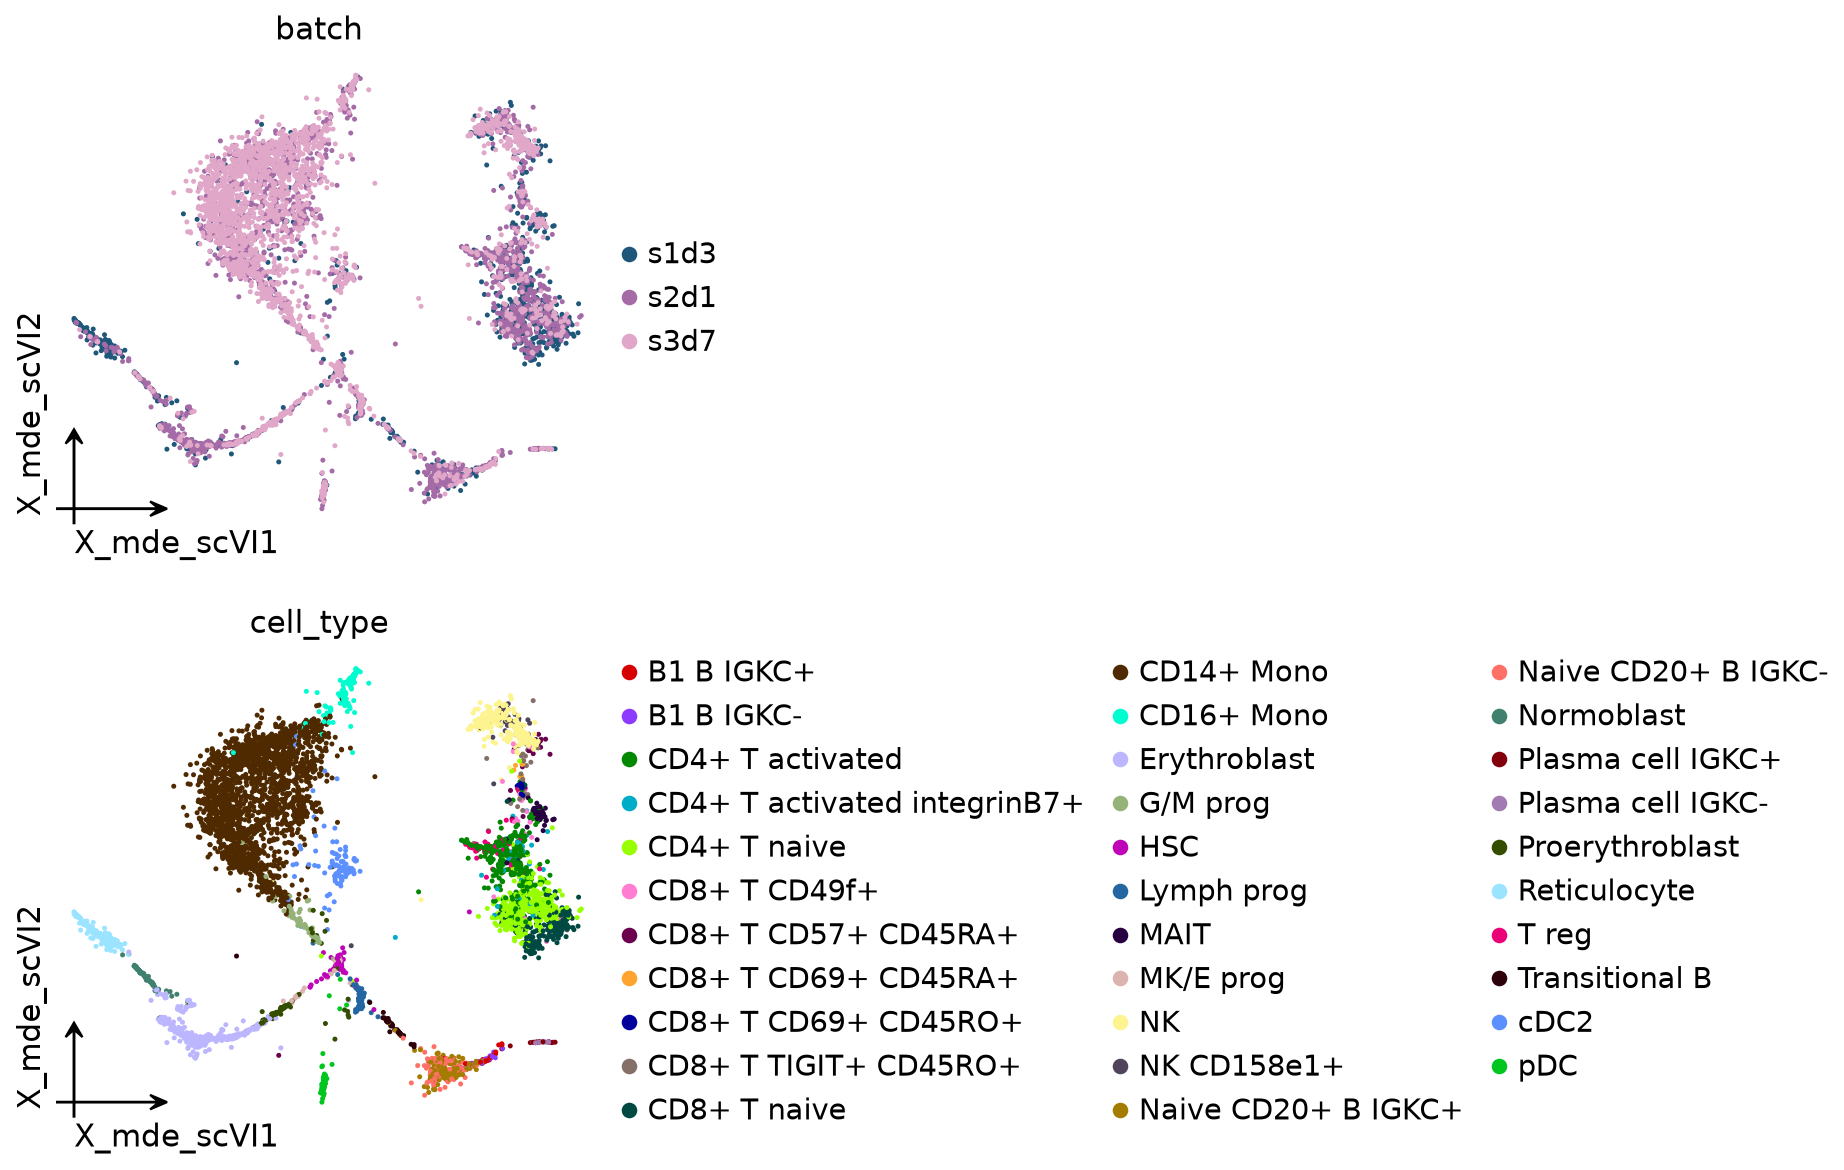

In [10]:
adata.obsm['X_mde_scVI'] = ov.vi.mde(adata.obsm['X_scVI'])
ov.pl.embedding(adata, basis='X_mde_scVI', color=['batch', 'cell_type'],
                frameon='small', wspace=0.65)

## How much batch effect was removed?

`ov.vi.integration_metrics` scores embeddings with `scib-metrics`
(`pip install scib-metrics`): batch removal (iLISI, kBET, batch ASW) and
bio conservation (cLISI, cell-type ASW, NMI / ARI of Leiden clusters, graph
connectivity); all in [0, 1], higher is better.

In [11]:
scores = ov.vi.integration_metrics(adata, ['X_pca', 'X_scVI'], batch_key='batch',
                                   label_key='cell_type', n_jobs=16)
scores.round(3)

INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


INFO     NK CD158e1+ consists of a single batch or is too small. Skip.                                             


           iLISI   kBET  ASW_batch  cLISI  ASW_label    NMI    ARI  graph_conn
embedding                                                                     
X_pca      0.021  0.411      0.589  0.999      0.592  0.751  0.572       0.779
X_scVI     0.445  0.818      0.838  0.995      0.543  0.798  0.719       0.800

Batch removal rises sharply from PCA to scVI (iLISI 0.02 → 0.45, kBET
0.41 → 0.82, batch ASW 0.59 → 0.84) while NMI / ARI and graph connectivity
improve and cLISI stays ≈ 1 — donors mix without cell types merging. The
cell-type silhouette dips slightly (0.59 → 0.54), as is typical for scVI, whose
latent is less compact than a PCA of the same genes.

## Key parameters

**Model** (→ `ov.vi.SCVI.__init__`; scvi-tools 1.5.2 defaults):
- `n_latent` (10), `n_hidden` (128), `n_layers` (1), `dropout_rate` (0.1).
- `gene_likelihood` ∈ {`'zinb'` (default), `'nb'`, `'poisson'`};
  `dispersion` ∈ {`'gene'`, `'gene-batch'`, `'gene-label'`, `'gene-cell'`}.
- `latent_distribution` ∈ {`'normal'`, `'ln'`}.
- `categorical_covariate_keys` / `continuous_covariate_keys` — extra
  covariates (e.g. sample, percent mito) injected into the decoder.
- `genes` — training genes (boolean mask, names or a `var` column such as
  `'highly_variable_features'`; with disk data only these columns are read).
- `use_batch_norm`, `use_layer_norm`, `encode_covariates`,
  `deeply_inject_covariates`, `use_observed_lib_size` — as scvi-tools.
- `seed` (0) — weight initialisation.

**Training** (→ `SCVI.train`):
- `max_epochs` (heuristic above), `batch_size` (128), `train_size` (0.9).
- `early_stopping` (False), `check_val_every_n_epoch`.
- `device` (`'auto'`, `'cuda'`, `'cuda:1'`, `'cpu'`); `devices=[0, 1, ...]` for
  multi-GPU data-parallel training.
- `lr` (1e-3), `weight_decay`, `n_epochs_kl_warmup` (400),
  `reduce_lr_on_plateau` — optimisation options.
- `precision` (`'32'` or `'bf16'`), `compile` / `cuda_graph` (`'auto'`).
- `shuffle`, `block_size`, `buffer_blocks` — block shuffling for disk data.


**Routing.** `ov.single.batch_correction` builds the `ov.vi` model with
`layer='counts'` (when that layer exists) and `batch_key=`, sends every keyword
the model constructor accepts there and every training / optimisation keyword
(`max_epochs`, `lr`, `n_epochs_kl_warmup`, ...) to `.train()`. scvi-tools
spellings are translated: `accelerator='gpu'` → `device='cuda'`,
`use_gpu=`, `enable_progress_bar=` → `progress=`; Lightning-only options
(`logger`, `trainer_config`, ...) are dropped.


**Outputs**: `adata.obsm['X_scVI']`; the returned model offers
`get_latent_representation`, `get_normalized_expression`,
`posterior_predictive_sample`, `history`, `save` / `ov.vi.SCVI.load`.

## Related tutorials

- [t_vi](../t_vi.ipynb) — the `ov.vi` API directly: in memory, from disk and on the GPU.
- [t_batch_scanvi](t_batch_scanvi.ipynb) — semi-supervised extension with label transfer.
- [t_batch_totalvi](t_batch_totalvi.ipynb) — joint RNA + protein for CITE-seq.
- [t_batch_harmony](t_batch_harmony.ipynb) — non-deep-learning alternative.

For the full side-by-side comparison with scib-metrics scoring, see
[../t_single_batch](../t_single_batch.ipynb).